# NIFTY 50 + Financial News: Full-Corpus vs Monthly-Sampled Analysis

Updated for the current finance-IDC pipeline.

This notebook compares `model_dataset.csv` (full-corpus baseline) with `model_dataset_sampled_monthly_2026.csv` (monthly-sampled experiment), checks data integrity, plots prices/returns/news/sentiment, and inspects the walk-forward comparison outputs.

It does **not** collect data, run FinBERT, rebuild datasets, or train models. Run `python src\monthly_sampling_experiment.py` before opening this notebook if you need fresh experiment outputs.

Open Jupyter from `C:\Users\surya\Documents\finance-IDC-Project`, select the `finance-IDC` kernel, then choose **Kernel → Restart Kernel and Run All Cells**.

## 1. Setup and locate data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

KNOWN_ROOT = Path(r"C:\Users\surya\Documents\finance-IDC-Project")
if (Path.cwd() / "data" / "processed").exists():
    PROJECT_ROOT = Path.cwd()
elif (KNOWN_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = KNOWN_ROOT
else:
    PROJECT_ROOT = Path.cwd()  # Set this manually if necessary.

DATA = PROJECT_ROOT / "data" / "processed"
print("Working directory:", Path.cwd())
print("Project root:", PROJECT_ROOT)
print("Data folder exists:", DATA.exists())
if not DATA.exists():
    raise FileNotFoundError("Set PROJECT_ROOT to the finance-IDC-Project folder.")

Working directory: C:\Users\surya\Documents\finance-IDC-Project
Project root: C:\Users\surya\Documents\finance-IDC-Project
Data folder exists: True


## 2. Load the baseline, sampled dataset, and experiment outputs

In [2]:
FILES = {
    "baseline": "model_dataset.csv",
    "sampled": "model_dataset_sampled_monthly_2026.csv",
    "market_daily": "news_market_daily.csv",
    "sentiment_daily": "news_sentiment_daily.csv",
    "sampled_sentiment_daily": "news_sentiment_daily_sampled_monthly_2026.csv",
    "return_comparison": "monthly_sampling_return_comparison.csv",
    "direction_comparison": "monthly_sampling_direction_comparison.csv",
    "paired_predictions": "monthly_sampling_paired_predictions.csv",
}
def load_csv(key):
    path = DATA / FILES[key]
    if not path.exists():
        print("Not found:", path.name)
        return None
    df = pd.read_csv(path)
    print(f"{path.name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    return df

baseline = load_csv("baseline")
sampled = load_csv("sampled")
market_daily = load_csv("market_daily")
sentiment_daily = load_csv("sentiment_daily")
sampled_sentiment_daily = load_csv("sampled_sentiment_daily")
return_comparison = load_csv("return_comparison")
direction_comparison = load_csv("direction_comparison")
paired_predictions = load_csv("paired_predictions")

if baseline is None or sampled is None:
    raise FileNotFoundError("Run the pipeline and monthly_sampling_experiment.py first.")
for df in (baseline, sampled):
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df.sort_values("date", inplace=True)
    df.reset_index(drop=True, inplace=True)
display(baseline.head())

model_dataset.csv: 1,438 rows × 18 columns
model_dataset_sampled_monthly_2026.csv: 1,438 rows × 18 columns
news_market_daily.csv: 1,438 rows × 13 columns
news_sentiment_daily.csv: 1,438 rows × 7 columns
news_sentiment_daily_sampled_monthly_2026.csv: 1,438 rows × 8 columns
monthly_sampling_return_comparison.csv: 6 rows × 5 columns
monthly_sampling_direction_comparison.csv: 4 rows × 6 columns
monthly_sampling_paired_predictions.csv: 432 rows × 24 columns


C:\Users\surya\AppData\Local\Temp\ipykernel_23672\3978381700.py:33: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("date", inplace=True)
C:\Users\surya\AppData\Local\Temp\ipykernel_23672\3978381700.py:34: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)
C:\Users\surya\AppData\Local\Temp\ipykernel_23672\3978381700.py:33: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("date", inplace=True)
C:\User

,date,open,high,low,close,volume,adj_close,daily_return,daily_return_pct,article_count,unique_sources,target_next_session_return_pct,target_next_session_date,mean_sentiment,median_sentiment,positive_fraction,negative_fraction,neutral_fraction
0,2021-01-01,13996.099609,14049.849609,13991.349609,14018.500000,358100.0,14018.500000,NaN,NaN,6,6,0.816067,2021-01-04,0.231023,0.116058,0.166667,0.000000,0.833333
1,2021-01-04,14104.349609,14147.950195,13953.750000,14132.900391,495000.0,14132.900391,0.008161,0.816067,11,10,0.471238,2021-01-05,0.084904,0.026357,0.272727,0.181818,0.545455
2,2021-01-05,14075.150391,14215.599609,14048.150391,14199.500000,492500.0,14199.500000,0.004712,0.471238,12,8,-0.375013,2021-01-06,0.214796,0.045868,0.250000,0.083333,0.666667
3,2021-01-06,14240.950195,14244.150391,14039.900391,14146.250000,632300.0,14146.250000,-0.003750,-0.375013,5,4,-0.062917,2021-01-07,0.117118,0.113086,0.400000,0.200000,0.400000
4,2021-01-07,14253.750000,14256.250000,14123.099609,14137.349609,559200.0,14137.349609,-0.000629,-0.062917,6,4,1.484722,2021-01-08,-0.297279,-0.031219,0.000000,0.333333,0.666667


## 3. Data integrity: same market/targets, separate news features

In [3]:
print("Baseline shape:", baseline.shape, "| Sampled shape:", sampled.shape)
print("Baseline dates:", baseline.date.min(), "to", baseline.date.max())
print("Sampled dates: ", sampled.date.min(), "to", sampled.date.max())
print("Duplicate dates:", int(baseline.date.duplicated().sum()), "(baseline),",
      int(sampled.date.duplicated().sum()), "(sampled)")

market_target_cols = [c for c in [
    "open", "high", "low", "close", "volume", "adj_close", "daily_return",
    "daily_return_pct", "target_next_session_return_pct", "target_next_session_date"
] if c in baseline.columns and c in sampled.columns]
news_cols = [c for c in [
    "article_count", "unique_sources", "mean_sentiment", "median_sentiment",
    "positive_fraction", "negative_fraction", "neutral_fraction"
] if c in baseline.columns and c in sampled.columns]

joined = baseline[["date"] + market_target_cols + news_cols].merge(
    sampled[["date"] + market_target_cols + news_cols],
    on="date", how="outer", suffixes=("_baseline", "_sampled"),
    indicator=True, validate="one_to_one"
)
display(joined["_merge"].value_counts().rename_axis("date_merge").to_frame("rows"))

rows = []
for col in market_target_cols + news_cols:
    a, b = joined[f"{col}_baseline"], joined[f"{col}_sampled"]
    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        diff = (pd.to_numeric(a, errors="coerce") - pd.to_numeric(b, errors="coerce")).abs() > 1e-9
        diff = diff.fillna(a.isna() ^ b.isna())
    else:
        diff = a.astype(str).ne(b.astype(str))
    rows.append({"column": col, "dates_different": int(diff.sum()),
                 "baseline_missing": int(a.isna().sum()), "sampled_missing": int(b.isna().sum())})
integrity = pd.DataFrame(rows)
display(integrity)
print("Expected: market and target columns match; news-related features may differ.")

Baseline shape: (1438, 18) | Sampled shape: (1438, 18)
Baseline dates: 2021-01-01 00:00:00 to 2026-10-28 00:00:00
Sampled dates:  2021-01-01 00:00:00 to 2026-10-28 00:00:00
Duplicate dates: 0 (baseline), 0 (sampled)


,rows
date_merge,
both,1438
left_only,0
right_only,0


,column,dates_different,baseline_missing,sampled_missing
0,open,0,0,0
1,high,0,0,0
2,low,0,0,0
3,close,0,0,0
4,volume,0,0,0
5,adj_close,0,0,0
6,daily_return,0,1,1
7,daily_return_pct,0,1,1
8,target_next_session_return_pct,0,1,1
9,target_next_session_date,1,1,1


Expected: market and target columns match; news-related features may differ.


## 4. NIFTY 50 market overview

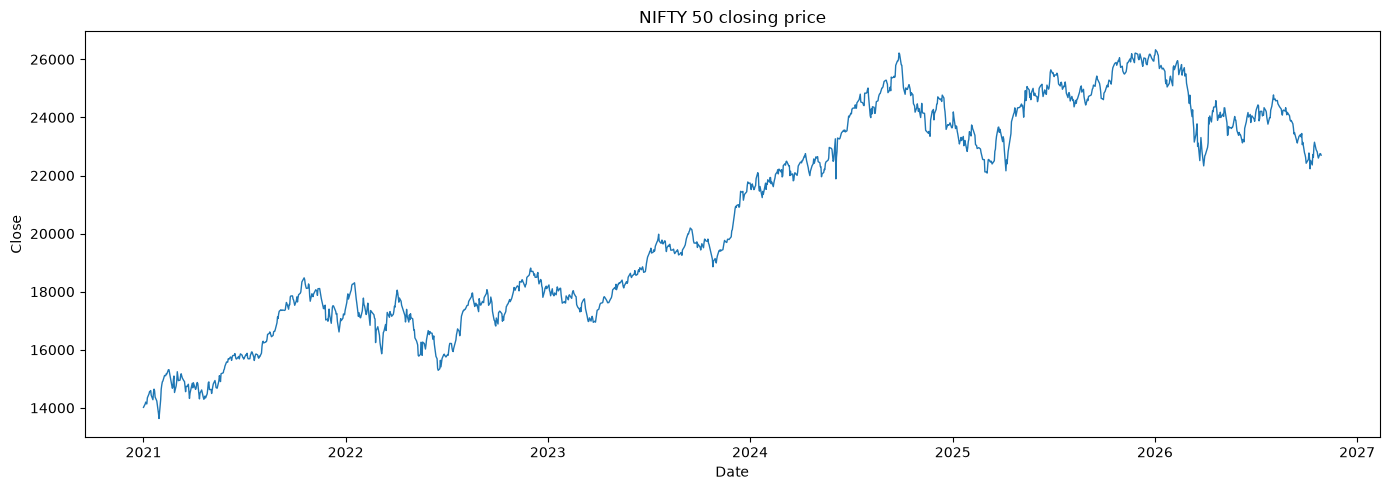

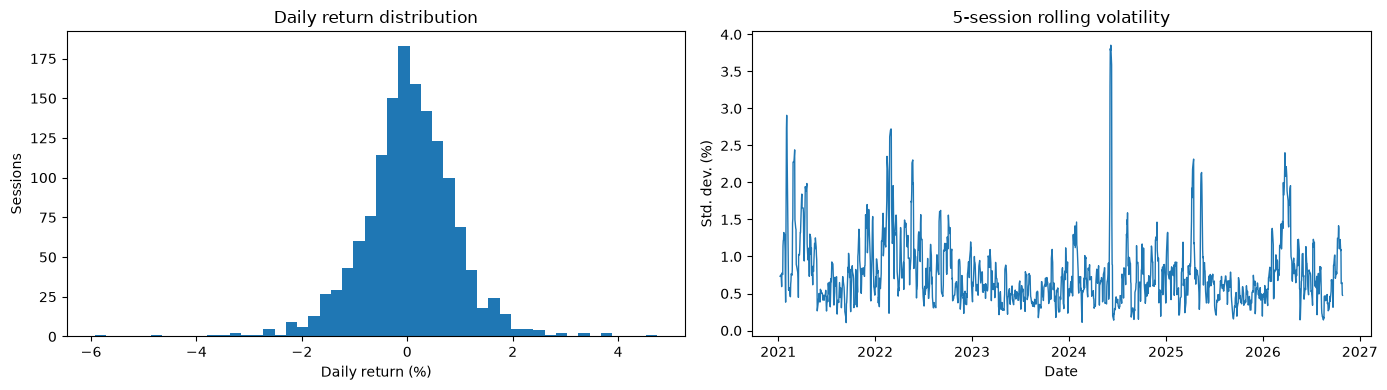

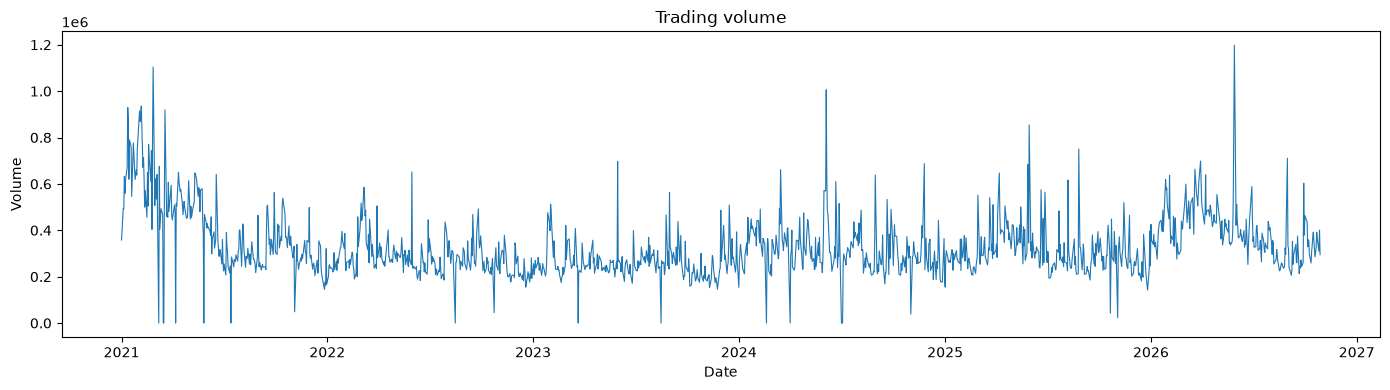

In [4]:
market = baseline.copy()
market["volatility_5"] = market["daily_return_pct"].rolling(5).std()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(market.date, market.close, linewidth=1)
ax.set(title="NIFTY 50 closing price", xlabel="Date", ylabel="Close")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(market["daily_return_pct"].dropna(), bins=50)
axes[0].set(title="Daily return distribution", xlabel="Daily return (%)", ylabel="Sessions")
axes[1].plot(market.date, market.volatility_5, linewidth=1)
axes[1].set(title="5-session rolling volatility", xlabel="Date", ylabel="Std. dev. (%)")
plt.tight_layout(); plt.show()

if "volume" in market:
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(market.date, market.volume, linewidth=.8)
    ax.set(title="Trading volume", xlabel="Date", ylabel="Volume")
    plt.tight_layout(); plt.show()

## 5. News volume and source diversity

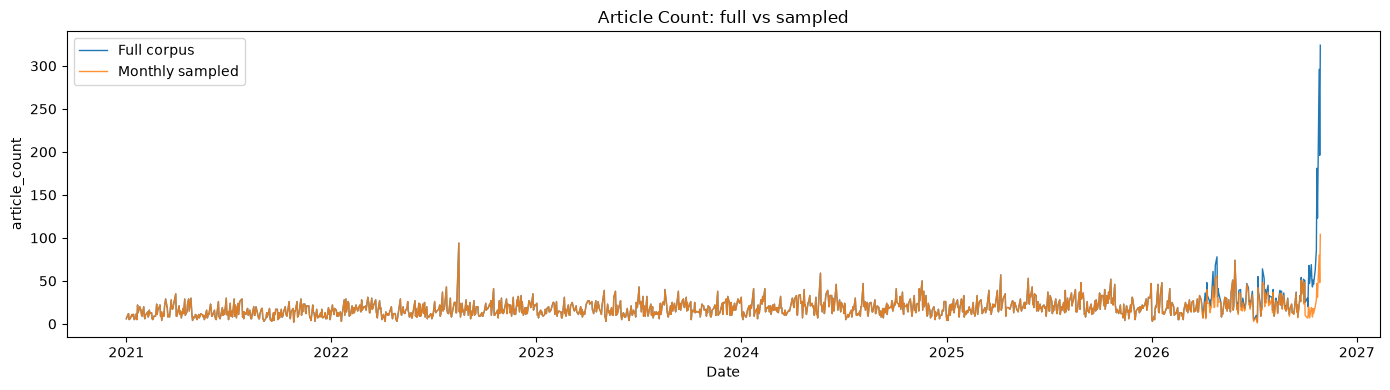

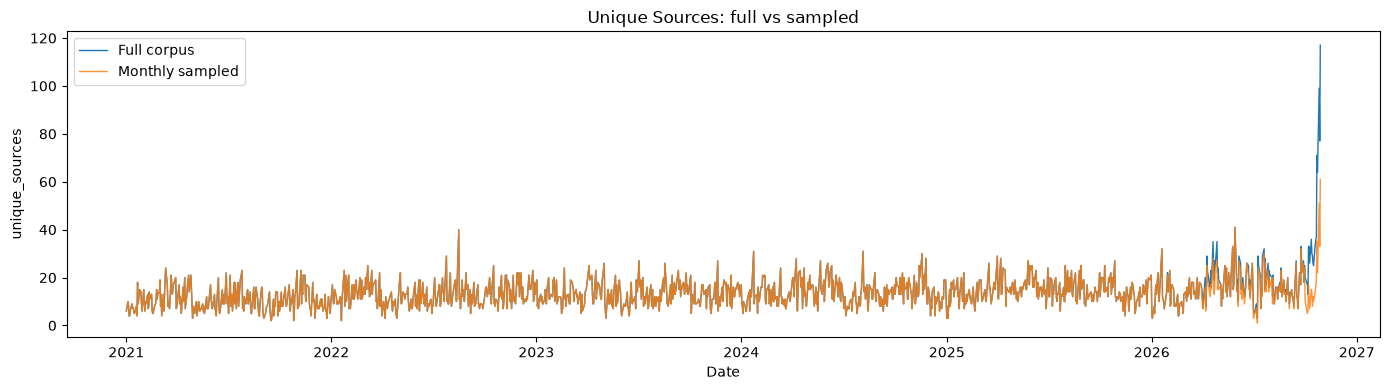

In [5]:
for col in ["article_count", "unique_sources"]:
    if col in baseline.columns and col in sampled.columns:
        fig, ax = plt.subplots(figsize=(14, 4))
        ax.plot(baseline.date, baseline[col], label="Full corpus", linewidth=1)
        ax.plot(sampled.date, sampled[col], label="Monthly sampled", linewidth=1, alpha=.85)
        ax.set(title=f"{col.replace('_', ' ').title()}: full vs sampled", xlabel="Date", ylabel=col)
        ax.legend(); plt.tight_layout(); plt.show()

## 6. Sentiment trends and distributions

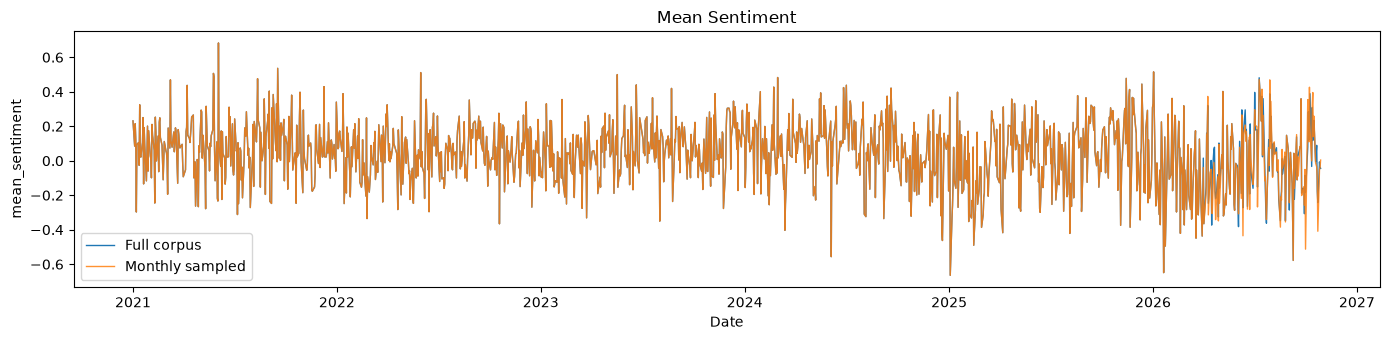

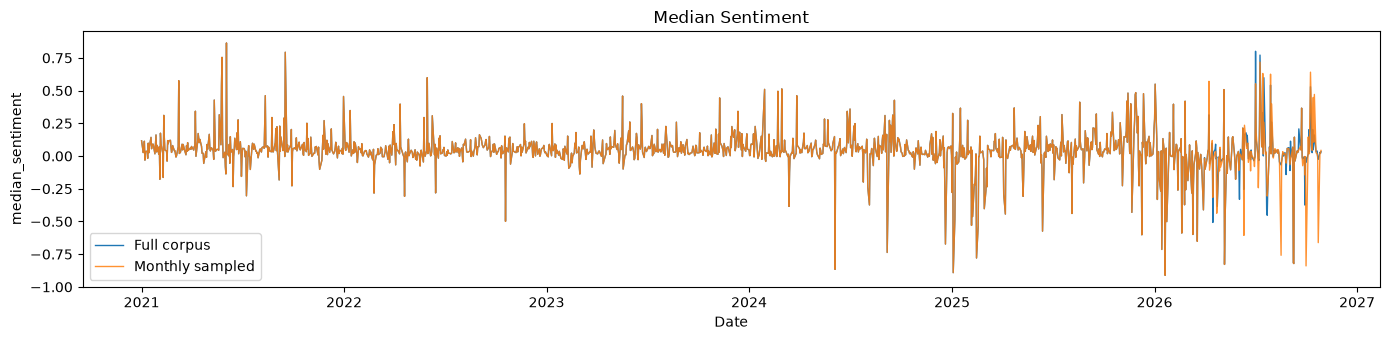

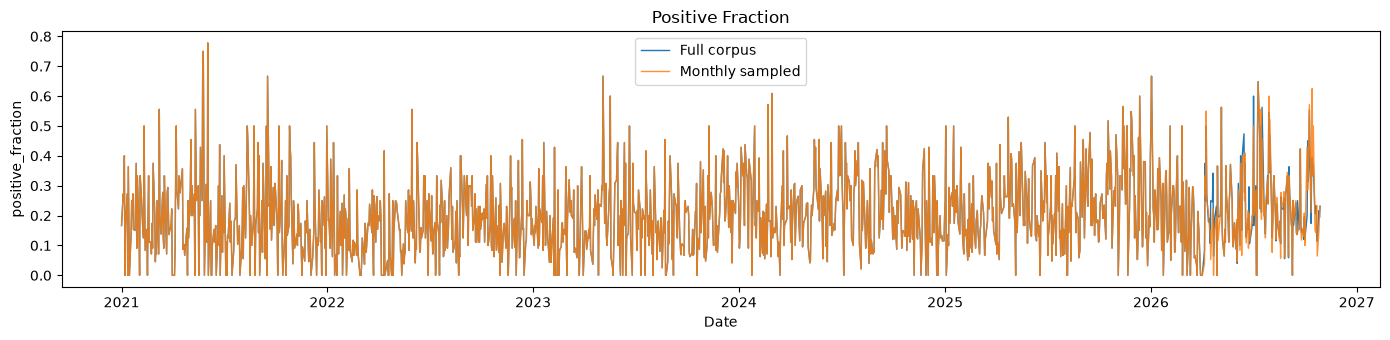

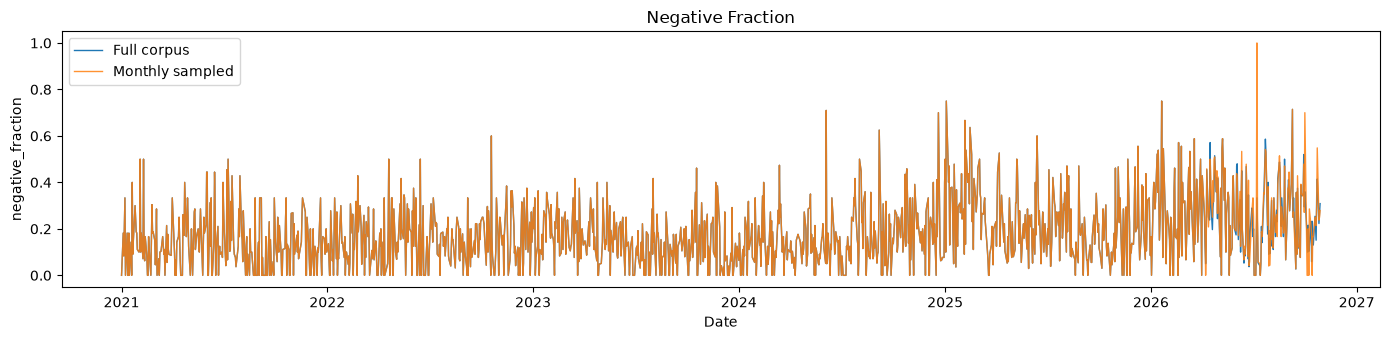

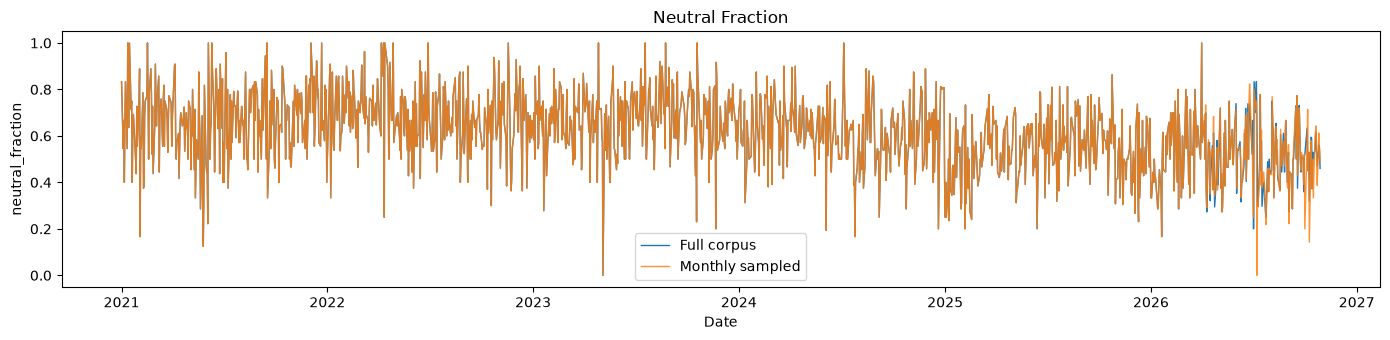

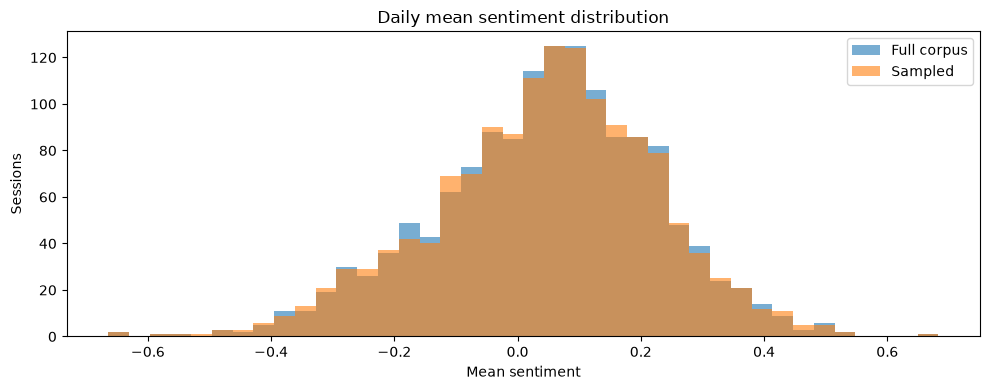

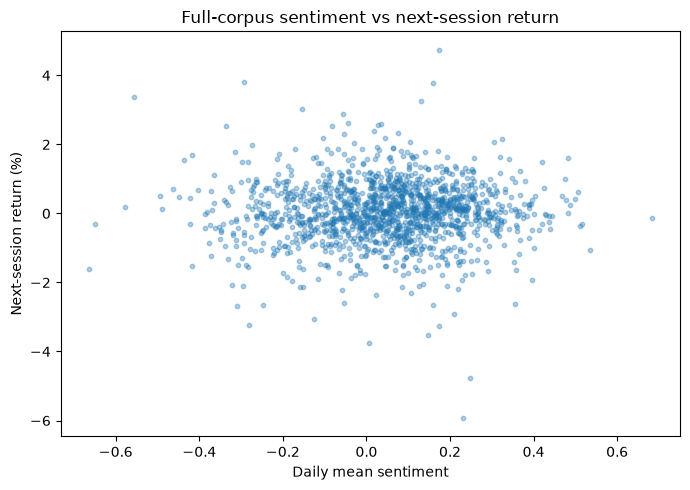

In [6]:
sent_cols = ["mean_sentiment", "median_sentiment", "positive_fraction",
             "negative_fraction", "neutral_fraction"]
available = [c for c in sent_cols if c in baseline.columns and c in sampled.columns]
for col in available:
    fig, ax = plt.subplots(figsize=(14, 3.5))
    ax.plot(baseline.date, baseline[col], label="Full corpus", linewidth=1)
    ax.plot(sampled.date, sampled[col], label="Monthly sampled", linewidth=1, alpha=.85)
    ax.set(title=col.replace("_", " ").title(), xlabel="Date", ylabel=col)
    ax.legend(); plt.tight_layout(); plt.show()

if "mean_sentiment" in baseline and "mean_sentiment" in sampled:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(baseline.mean_sentiment.dropna(), bins=40, alpha=.6, label="Full corpus")
    ax.hist(sampled.mean_sentiment.dropna(), bins=40, alpha=.6, label="Sampled")
    ax.set(title="Daily mean sentiment distribution", xlabel="Mean sentiment", ylabel="Sessions")
    ax.legend(); plt.tight_layout(); plt.show()

if "mean_sentiment" in baseline and "target_next_session_return_pct" in baseline:
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(baseline.mean_sentiment, baseline.target_next_session_return_pct, s=10, alpha=.35)
    ax.set(title="Full-corpus sentiment vs next-session return",
           xlabel="Daily mean sentiment", ylabel="Next-session return (%)")
    plt.tight_layout(); plt.show()

## 7. Walk-forward experiment results

In [7]:
if return_comparison is not None:
    print("Return prediction metrics (lower MAE/RMSE is better; higher R² is better):")
    display(return_comparison)
if direction_comparison is not None:
    print("Direction metrics (higher accuracy can be misleading; also inspect Brier score):")
    display(direction_comparison)
if paired_predictions is not None:
    print("Paired predictions preview:")
    display(paired_predictions.head())
    print("Paired rows:", len(paired_predictions))

Return prediction metrics (lower MAE/RMSE is better; higher R² is better):


,dataset,model,MAE_pct,RMSE_pct,R2
0,Original,Mean baseline,0.613758,0.831298,-0.003427
1,Original,Market + news volume,0.624972,0.838340,-0.020499
2,Original,Market + news + sentiment,0.631221,0.842992,-0.031856
3,Monthly sampled,Mean baseline,0.613758,0.831298,-0.003427
4,Monthly sampled,Market + news volume,0.620557,0.835040,-0.012482
5,Monthly sampled,Market + news + sentiment,0.627544,0.840384,-0.025481


Direction metrics (higher accuracy can be misleading; also inspect Brier score):


,dataset,model,accuracy,brier_score,high_confidence_count,high_confidence_accuracy
0,Original,market,0.469907,0.257128,36,0.527778
1,Original,sentiment,0.504630,0.257968,108,0.481481
2,Monthly sampled,market,0.481481,0.255242,33,0.545455
3,Monthly sampled,sentiment,0.518519,0.256417,95,0.484211


Paired predictions preview:


,date,target_next_session_date,actual_return_pct_original,actual_up_original,mean_baseline_prediction_pct_original,market_prediction_pct_original,sentiment_prediction_pct_original,market_p_up_original,market_predicted_up_original,market_confidence_original,sentiment_p_up_original,sentiment_predicted_up_original,sentiment_confidence_original,actual_return_pct_sampled,actual_up_sampled,mean_baseline_prediction_pct_sampled,market_prediction_pct_sampled,sentiment_prediction_pct_sampled,market_p_up_sampled,market_predicted_up_sampled,market_confidence_sampled,sentiment_p_up_sampled,sentiment_predicted_up_sampled,sentiment_confidence_sampled
0,2025-01-27,2025-01-28,0.561123,1,0.052703,0.122305,0.110837,0.531872,1,0.531872,0.487199,0,0.512801,0.561123,1,0.052703,0.122305,0.110837,0.531872,1,0.531872,0.487199,0,0.512801
1,2025-01-28,2025-01-29,0.896665,1,0.053209,0.207930,0.244089,0.631075,1,0.631075,0.627030,1,0.627030,0.896665,1,0.053209,0.207930,0.244089,0.631075,1,0.631075,0.627030,1,0.627030
2,2025-01-29,2025-01-30,0.373009,1,0.054046,0.101093,0.196311,0.572464,1,0.572464,0.623098,1,0.623098,0.373009,1,0.054046,0.101093,0.196311,0.572464,1,0.572464,0.623098,1,0.623098
3,2025-01-30,2025-01-31,1.113574,1,0.054363,0.004066,0.124849,0.543127,1,0.543127,0.607830,1,0.607830,1.113574,1,0.054363,0.004066,0.124849,0.543127,1,0.543127,0.607830,1,0.607830
4,2025-01-31,2025-02-01,-0.111662,0,0.055413,0.116229,0.107955,0.608031,1,0.608031,0.586245,1,0.586245,-0.111662,0,0.055413,0.116229,0.107955,0.608031,1,0.608031,0.586245,1,0.586245


Paired rows: 432


## 8. Paired forecast validation and error comparison

In [8]:
if paired_predictions is None:
    print("Paired predictions file not found. Run monthly_sampling_experiment.py.")
else:
    pp = paired_predictions.copy()
    print("Columns available:", pp.columns.tolist())
    actual_o = "actual_return_pct_original"
    actual_s = "actual_return_pct_sampled"
    pred_o = "sentiment_prediction_pct_original"
    pred_s = "sentiment_prediction_pct_sampled"

    if all(c in pp.columns for c in [actual_o, actual_s]):
        ao = pd.to_numeric(pp[actual_o], errors="coerce")
        ass = pd.to_numeric(pp[actual_s], errors="coerce")
        print("Rows with mismatched actual returns:", int(((ao - ass).abs() > 1e-9).sum()))
    else:
        print("Could not find both suffixed actual-return columns; check the column list above.")

    if all(c in pp.columns for c in [actual_o, actual_s, pred_o, pred_s]):
        actual = pd.to_numeric(pp[actual_o], errors="coerce")
        pred_full = pd.to_numeric(pp[pred_o], errors="coerce")
        pred_sampled = pd.to_numeric(pp[pred_s], errors="coerce")
        valid = actual.notna() & pd.to_numeric(pp[actual_s], errors="coerce").notna() & pred_full.notna() & pred_sampled.notna()
        e_full = pred_full[valid] - actual[valid]
        e_sampled = pred_sampled[valid] - actual[valid]
        paired_metrics = pd.DataFrame([
            {"dataset":"Full corpus", "n":int(valid.sum()), "MAE":e_full.abs().mean(), "RMSE":np.sqrt((e_full**2).mean())},
            {"dataset":"Monthly sampled", "n":int(valid.sum()), "MAE":e_sampled.abs().mean(), "RMSE":np.sqrt((e_sampled**2).mean())},
        ])
        display(paired_metrics)
        delta = e_full.abs() - e_sampled.abs()
        print("Mean absolute-error difference (full minus sampled):", round(float(delta.mean()), 6))
        print("Positive means sampled errors are lower on average; this is descriptive, not a significance test.")
    else:
        print("Prediction columns for the sentiment return model were not found. Inspect the listed columns.")

Columns available: ['date', 'target_next_session_date', 'actual_return_pct_original', 'actual_up_original', 'mean_baseline_prediction_pct_original', 'market_prediction_pct_original', 'sentiment_prediction_pct_original', 'market_p_up_original', 'market_predicted_up_original', 'market_confidence_original', 'sentiment_p_up_original', 'sentiment_predicted_up_original', 'sentiment_confidence_original', 'actual_return_pct_sampled', 'actual_up_sampled', 'mean_baseline_prediction_pct_sampled', 'market_prediction_pct_sampled', 'sentiment_prediction_pct_sampled', 'market_p_up_sampled', 'market_predicted_up_sampled', 'market_confidence_sampled', 'sentiment_p_up_sampled', 'sentiment_predicted_up_sampled', 'sentiment_confidence_sampled']
Rows with mismatched actual returns: 0


,dataset,n,MAE,RMSE
0,Full corpus,432,0.631221,0.842992
1,Monthly sampled,432,0.627544,0.840384


Mean absolute-error difference (full minus sampled): 0.003677
Positive means sampled errors are lower on average; this is descriptive, not a significance test.


## 9. Missingness and correlation checks

,baseline_missing,sampled_missing
daily_return_pct,1,1
daily_return,1,1
target_next_session_date,1,1
target_next_session_return_pct,1,1
article_count,0,0
adj_close,0,0
high,0,0
low,0,0
close,0,0
date,0,0


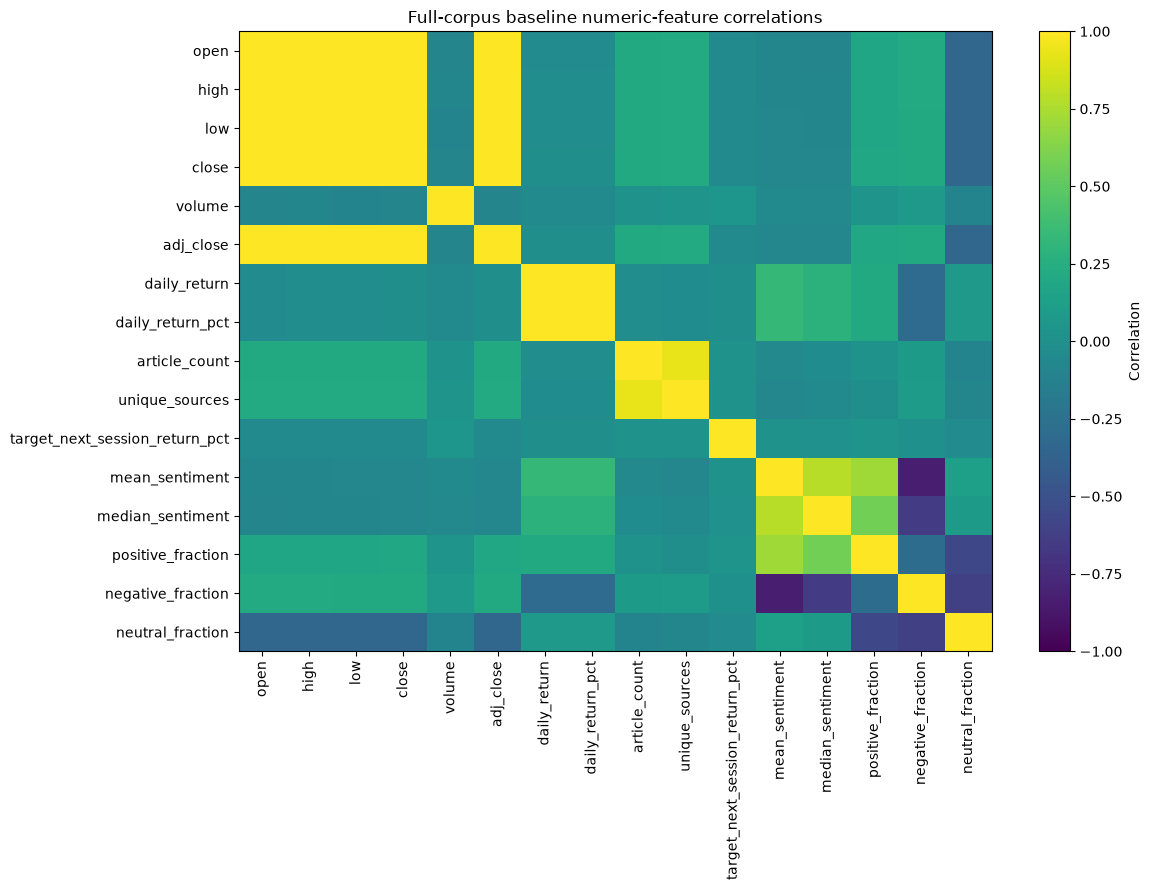

In [9]:
display(pd.DataFrame({
    "baseline_missing": baseline.isna().sum(),
    "sampled_missing": sampled.isna().sum()
}).sort_values("baseline_missing", ascending=False))

numeric = baseline.select_dtypes(include=np.number)
if numeric.shape[1] >= 2:
    corr = numeric.corr()
    fig, ax = plt.subplots(figsize=(12, 9))
    im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index)
    ax.set_title("Full-corpus baseline numeric-feature correlations")
    fig.colorbar(im, ax=ax, label="Correlation")
    plt.tight_layout(); plt.show()

## 10. Summary

In [10]:
print("=== SUMMARY ===")
print(f"Baseline: {len(baseline):,} rows; sampled: {len(sampled):,} rows")
print(f"Baseline date range: {baseline.date.min().date()} to {baseline.date.max().date()}")
print(f"Sampled date range:  {sampled.date.min().date()} to {sampled.date.max().date()}")
if "target_next_session_return_pct" in baseline:
    target = pd.to_numeric(baseline.target_next_session_return_pct, errors="coerce")
    print("Available targets:", int(target.notna().sum()), "| Missing targets:", int(target.isna().sum()))
print("Use the saved walk-forward tables for model evaluation. Small differences are not proof of improvement.")
print("The main dataset is the full-corpus baseline; the sampled dataset remains a separate experiment.")

=== SUMMARY ===
Baseline: 1,438 rows; sampled: 1,438 rows
Baseline date range: 2021-01-01 to 2026-10-28
Sampled date range:  2021-01-01 to 2026-10-28
Available targets: 1437 | Missing targets: 1
Use the saved walk-forward tables for model evaluation. Small differences are not proof of improvement.
The main dataset is the full-corpus baseline; the sampled dataset remains a separate experiment.
